In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Importing librarary
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
#load data set
df = pd.read_csv("employee_salary_dataset_500.csv")

In [ ]:
#print Datset
print(df)

      Age  Experience_Years Education  Department Job_Level  \
0    59.0              36.0       PhD       Sales       Mid   
1    49.0              29.0  Bachelor          HR      Lead   
2    35.0               9.0    Master  Operations    Junior   
3    28.0               2.0       PhD   Marketing    Senior   
4    41.0              20.0  bachelor       Sales       Mid   
..    ...               ...       ...         ...       ...   
495  40.0              11.0       NaN          HR    Senior   
496  49.0              29.0  Bachelor          HR      Lead   
497  21.0               2.0  Bachelor          IT    Junior   
498  44.0              20.0  Bachelor          HR    Junior   
499  50.0              26.0    Master     Finance       Mid   

     Performance_Score  Weekly_Hours Favorite_Color  Shoe_Size  Salary  
0                  2.4          45.0           Blue        9.0  180000  
1                  4.6          44.0          Green        7.0  180000  
2                  4.1  

In [ ]:
#using head()
df.head(7)

,Age,Experience_Years,Education,Department,Job_Level,Performance_Score,Weekly_Hours,Favorite_Color,Shoe_Size,Salary
0,59.0,36.0,PhD,Sales,Mid,2.4,45.0,Blue,9.0,180000
1,49.0,29.0,Bachelor,HR,Lead,4.6,44.0,Green,7.0,180000
2,35.0,9.0,Master,Operations,Junior,4.1,42.0,Blue,9.0,134100
3,28.0,2.0,PhD,Marketing,Senior,4.7,52.0,Blue,10.0,121500
4,41.0,20.0,bachelor,Sales,Mid,2.4,NaN,Black,9.0,136700
5,59.0,37.0,Master,HR,Mid,3.8,NaN,Green,12.0,176200
6,39.0,9.0,Bachelor,Operations,Senior,3.8,32.0,Black,11.0,127900


In [ ]:
#using tail
df.tail()

,Age,Experience_Years,Education,Department,Job_Level,Performance_Score,Weekly_Hours,Favorite_Color,Shoe_Size,Salary
495,40.0,11.0,NaN,HR,Senior,3.7,44.0,NaN,9.0,139700
496,49.0,29.0,Bachelor,HR,Lead,4.6,44.0,Green,7.0,180000
497,21.0,2.0,Bachelor,IT,Junior,4.3,54.0,Green,9.0,104400
498,44.0,20.0,Bachelor,HR,Junior,2.8,60.0,Blue,9.0,130200
499,50.0,26.0,Master,Finance,Mid,4.8,49.0,Blue,12.0,180000


In [ ]:
#using shape
df.shape

(500, 10)

In [ ]:
#using info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                488 non-null    float64
 1   Experience_Years   485 non-null    float64
 2   Education          485 non-null    object 
 3   Department         488 non-null    object 
 4   Job_Level          482 non-null    object 
 5   Performance_Score  481 non-null    float64
 6   Weekly_Hours       489 non-null    float64
 7   Favorite_Color     480 non-null    object 
 8   Shoe_Size          486 non-null    float64
 9   Salary             500 non-null    int64  
dtypes: float64(5), int64(1), object(4)
memory usage: 39.2+ KB


In [ ]:
#using describe
df.describe()

,Age,Experience_Years,Performance_Score,Weekly_Hours,Shoe_Size,Salary
count,488.000000,485.000000,481.000000,489.000000,486.000000,500.000000
mean,41.540984,17.882474,3.555717,44.975460,8.664609,143799.000000
std,11.752162,11.500835,0.874698,8.905895,2.345573,30443.670823
min,21.000000,0.000000,2.000000,30.000000,5.000000,65900.000000
25%,31.750000,7.000000,2.800000,37.000000,7.000000,120775.000000
50%,43.000000,19.000000,3.600000,45.000000,9.000000,149300.000000
75%,52.000000,28.000000,4.300000,53.000000,11.000000,171900.000000
max,60.000000,42.000000,5.000000,60.000000,12.000000,180000.000000


In [ ]:
#count null value
df.isnull().sum()

Age                  12
Experience_Years     15
Education            15
Department           12
Job_Level            18
Performance_Score    19
Weekly_Hours         11
Favorite_Color       20
Shoe_Size            14
Salary                0
dtype: int64

In [ ]:
#check the columns
print(df.columns)

Index(['Age', 'Experience_Years', 'Education', 'Department', 'Job_Level',
       'Performance_Score', 'Weekly_Hours', 'Favorite_Color', 'Shoe_Size',
       'Salary'],
      dtype='object')


In [ ]:
#Calculate missing-value percentage:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Age                  2.4
Experience_Years     3.0
Education            3.0
Department           2.4
Job_Level            3.6
Performance_Score    3.8
Weekly_Hours         2.2
Favorite_Color       4.0
Shoe_Size            2.8
Salary               0.0
dtype: float64


In [ ]:
#You can also create a table:
missing_table = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

print(missing_table)

                   Missing_Count  Missing_Percentage
Age                           12                 2.4
Experience_Years              15                 3.0
Education                     15                 3.0
Department                    12                 2.4
Job_Level                     18                 3.6
Performance_Score             19                 3.8
Weekly_Hours                  11                 2.2
Favorite_Color                20                 4.0
Shoe_Size                     14                 2.8
Salary                         0                 0.0


In [ ]:
#— Find duplicate records

In [ ]:
duplicate_count = df.duplicated().sum()


In [ ]:
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 12


In [ ]:
duplicates = df[df.duplicated(keep=False)]

print(duplicates)

      Age  Experience_Years Education  Department Job_Level  \
1    49.0              29.0  Bachelor          HR      Lead   
57   38.0              16.0    Master  Operations    Senior   
116  34.0              16.0       PhD   Marketing       NaN   
128  50.0              26.0    Master     Finance       Mid   
176  43.0              20.0    Master          HR    Senior   
185  26.0               5.0  Bachelor   Marketing    Junior   
230  21.0               2.0  Bachelor          IT    Junior   
233  57.0              31.0    Master     Finance       NaN   
266  40.0              11.0       NaN          HR    Senior   
304  52.0              28.0  Bachelor   Marketing       NaN   
371  46.0              19.0  Bachelor   Marketing    Junior   
469  44.0              20.0  Bachelor          HR    Junior   
488  26.0               5.0  Bachelor   Marketing    Junior   
489  52.0              28.0  Bachelor   Marketing       NaN   
490  57.0              31.0    Master     Finance      

In [ ]:
#Remove duplicates:
df1 = df.copy()
df1 = df.drop_duplicates()

In [ ]:
print("Rows before removing duplicates:", len(df))
print("Rows after removing duplicates:", len(df1))

Rows before removing duplicates: 500
Rows after removing duplicates: 488


In [ ]:
#Remove unrelated columns
df1 = df1.drop(
    columns=["Favorite_Color", "Shoe_Size"]
)

In [ ]:
print(df1.columns)

Index(['Age', 'Experience_Years', 'Education', 'Department', 'Job_Level',
       'Performance_Score', 'Weekly_Hours', 'Salary'],
      dtype='object')


In [ ]:
#see only Age and Salary
df1[['Age','Salary']].head(10)

,Age,Salary
0,59.0,180000
1,49.0,180000
2,35.0,134100
3,28.0,121500
4,41.0,136700
5,59.0,176200
6,39.0,127900
7,43.0,180000
8,31.0,152900
9,31.0,98300


In [ ]:
#Data Transformation
def get_career_stage(age):
    if age <= 25:
        return 'Entry-Level'
    elif age <= 32:
        return 'Mid-Level '
    elif age <= 45:
        return 'Senior-Level'
    else:
        return 'Executive-Level'



In [ ]:
# Apply the function to create new column
df1['Career Stage'] = df1['Age'].apply(get_career_stage)



In [ ]:
# See result
df1[['Age', 'Career Stage']].head(10)

,Age,Career Stage
0,59.0,Executive-Level
1,49.0,Executive-Level
2,35.0,Senior-Level
3,28.0,Mid-Level
4,41.0,Senior-Level
5,59.0,Executive-Level
6,39.0,Senior-Level
7,43.0,Senior-Level
8,31.0,Mid-Level
9,31.0,Mid-Level


In [ ]:
#handle the misssing value
df1.isnull().sum()

Age                  12
Experience_Years     15
Education            14
Department           12
Job_Level            15
Performance_Score    19
Weekly_Hours         11
Salary                0
Career Stage          0
dtype: int64

In [ ]:
# 2. Fill with Mean (most common for Age)
print(df1['Age'].mean())



41.53781512605042


In [ ]:
df1['Age'] = df1['Age'].fillna(df1['Age'].mean())

In [ ]:
df1['Experience_Years'] = df1['Experience_Years'].fillna(df1['Experience_Years'].mean())

In [ ]:
df1['Education'] = df1['Education'].fillna(df1['Education'].mode())

In [ ]:
df1.head(5)

,Age,Experience_Years,Education,Department,Job_Level,Performance_Score,Weekly_Hours,Salary,Career Stage
0,59.0,36.0,PhD,Sales,Mid,2.4,45.0,180000,Executive-Level
1,49.0,29.0,Bachelor,HR,Lead,4.6,44.0,180000,Executive-Level
2,35.0,9.0,Master,Operations,Junior,4.1,42.0,134100,Senior-Level
3,28.0,2.0,PhD,Marketing,Senior,4.7,52.0,121500,Mid-Level
4,41.0,20.0,bachelor,Sales,Mid,2.4,NaN,136700,Senior-Level


In [ ]:
# 3. Fill with Median (best if data has outliers)
print(df1['Age'].mean())
# 4. Fill with Mode
print(df1['Age'].mode())

41.53781512605043
0    53.0
Name: Age, dtype: float64


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 488 entries, 0 to 487
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                488 non-null    float64
 1   Experience_Years   488 non-null    float64
 2   Education          474 non-null    object 
 3   Department         476 non-null    object 
 4   Job_Level          473 non-null    object 
 5   Performance_Score  469 non-null    float64
 6   Weekly_Hours       477 non-null    float64
 7   Salary             488 non-null    int64  
 8   Career Stage       488 non-null    object 
dtypes: float64(4), int64(1), object(4)
memory usage: 38.1+ KB


In [ ]:
# 1. Department -> forward fill (ffill)
df1['Department'] = df1['Department'].ffill()

# 2. Job Level -> backward fill (bfill)
df1['Job_Level'] = df1['Job_Level'].bfill()

# 3. Performance_Score -> average (mean)
df1['Performance_Score'] = df1['Performance_Score'].fillna(df1['Performance_Score'].mean())

# 4. Weekly_Hours -> average (mean)
df1['Weekly_Hours'] = df1['Weekly_Hours'].fillna(df1['Weekly_Hours'].mean())


In [ ]:
df1['Education'] = df1['Education'].ffill()

In [ ]:
# Verify no missing left
df1.isnull().sum()

Age                  0
Experience_Years     0
Education            0
Department           0
Job_Level            0
Performance_Score    0
Weekly_Hours         0
Salary               0
Career Stage         0
dtype: int64

In [ ]:
#df_clean = df1.dropna(subset=['Experience_Years', 'Education'])

In [ ]:
df1.isnull().sum()

Age                  0
Experience_Years     0
Education            0
Department           0
Job_Level            0
Performance_Score    0
Weekly_Hours         0
Salary               0
Career Stage         0
dtype: int64

In [ ]:
# 1. Remove leading/trailing spaces
df1['Education'] = df1['Education'].str.strip()

In [ ]:
df1["Education"].head()

0         PhD
1    Bachelor
2      Master
3         PhD
4    bachelor
Name: Education, dtype: object

In [ ]:
#Make all lowercase / uppercase to make it uniform
df1['Education'] = df1['Education'].str.title()  # or .str.upper() or .str.title()

In [ ]:
df1["Education"].head()

0         Phd
1    Bachelor
2      Master
3         Phd
4    Bachelor
Name: Education, dtype: object

In [ ]:
#check unique value of col
df1['Education'].unique()


array(['Phd', 'Bachelor', 'Master'], dtype=object)

In [ ]:
# Remove all rows with any NaN
df1 = df1.dropna()

In [ ]:
df1['Education'].unique()

array(['Phd', 'Bachelor', 'Master'], dtype=object)

In [ ]:
# ================= 1. UNIVARIATE ANALYSIS =================

In [ ]:
# Numeric columns
df1[['Age', 'Experience_Years', 'Performance_Score', 'Weekly_Hours']].describe()

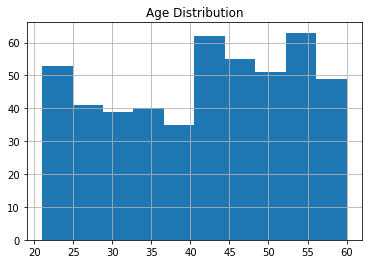

In [ ]:
# Distribution of each numeric column
#bins=10 = 10 bars (broad)
df1['Age'].hist(bins=10)
plt.title('Age Distribution')
plt.show()

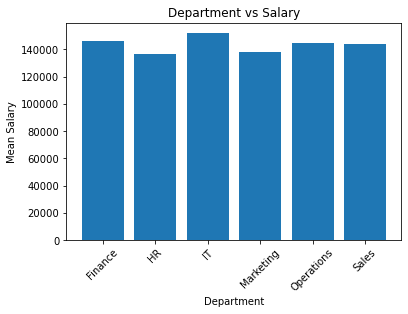

In [ ]:
# ================= 2. BIVARIATE ANALYSIS =================
import matplotlib.pyplot as plt

# 1. Department vs Salary (Bar - mean)
mean_salary = df1.groupby("Department")["Salary"].mean()
plt.bar(mean_salary.index, mean_salary.values)
plt.xticks(rotation=45)
plt.xlabel("Department")
plt.ylabel("Mean Salary")
plt.title("Department vs Salary")
plt.show()

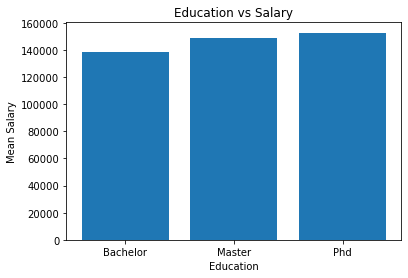

In [ ]:
# Education vs Salary (Bar)
mean_edu = df1.groupby("Education")["Salary"].mean()
plt.bar(mean_edu.index, mean_edu.values)
plt.xlabel("Education")
plt.ylabel("Mean Salary")
plt.title("Education vs Salary")
plt.show()

In [ ]:
df1.groupby('Department')['Performance_Score'].mean()

Department
Finance       3.645010
HR            3.523172
IT            3.462162
Marketing     3.629648
Operations    3.675195
Sales         3.339846
Name: Performance_Score, dtype: float64

In [ ]:
df1.groupby('Department')['Salary'].mean()

Department
Finance       146413.095238
HR            136680.281690
IT            152086.486486
Marketing     138046.428571
Operations    144782.142857
Sales         144185.714286
Name: Salary, dtype: float64

In [ ]:
df1.columns.tolist()
df1

,Age,Experience_Years,Education,Department,Job_Level,Performance_Score,Weekly_Hours,Salary,Career Stage
0,59.0,36.0,Phd,Sales,Mid,2.4,45.000000,180000,Executive-Level
1,49.0,29.0,Bachelor,HR,Lead,4.6,44.000000,180000,Executive-Level
2,35.0,9.0,Master,Operations,Junior,4.1,42.000000,134100,Senior-Level
3,28.0,2.0,Phd,Marketing,Senior,4.7,52.000000,121500,Mid-Level
4,41.0,20.0,Bachelor,Sales,Mid,2.4,44.974843,136700,Senior-Level
...,...,...,...,...,...,...,...,...,...
483,45.0,14.0,Bachelor,Sales,Senior,3.3,46.000000,148800,Senior-Level
484,55.0,27.0,Bachelor,Operations,Junior,2.5,52.000000,153800,Executive-Level
485,50.0,30.0,Bachelor,Marketing,Senior,2.5,37.000000,173300,Executive-Level
486,37.0,8.0,Phd,IT,Mid,2.3,50.000000,151000,Senior-Level


In [ ]:
#Remove unrelated columns
df2 = df1.drop(
    columns=["Department","Job_Level","Career Stage",'Job_Level',"Weekly_Hours"]
)

In [ ]:
#Check missing values again
print(df2.isnull().sum())

Age                  0
Experience_Years     0
Education            0
Performance_Score    0
Salary               0
dtype: int64


In [ ]:
#Separate independent variables and target variable
#Our target variable is Salary
X = df2.drop(columns=["Salary"])

y = df2["Salary"]

In [ ]:
#print("X:")
print(X.head())

print("\n y Target:")
print(y.head())

    Age  Experience_Years Education  Performance_Score
0  59.0              36.0       Phd                2.4
1  49.0              29.0  Bachelor                4.6
2  35.0               9.0    Master                4.1
3  28.0               2.0       Phd                4.7
4  41.0              20.0  Bachelor                2.4

 y Target:
0    180000
1    180000
2    134100
3    121500
4    136700
Name: Salary, dtype: int64


In [ ]:
#Identify numerical and categorical columns
numeric_features = [
    "Age",
    "Experience_Years",
    "Performance_Score",

]

In [ ]:
#categorical column
categorical_features = [
    "Education",

]

In [ ]:
print(X.head(2))

    Age  Experience_Years Education  Performance_Score
0  59.0              36.0       Phd                2.4
1  49.0              29.0  Bachelor                4.6


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df2['Education_num'] = le.fit_transform(df2['Education'])


In [ ]:
df2

,Age,Experience_Years,Education,Performance_Score,Salary,Education_num
0,59.0,36.0,Phd,2.4,180000,2
1,49.0,29.0,Bachelor,4.6,180000,0
2,35.0,9.0,Master,4.1,134100,1
3,28.0,2.0,Phd,4.7,121500,2
4,41.0,20.0,Bachelor,2.4,136700,0
...,...,...,...,...,...,...
483,45.0,14.0,Bachelor,3.3,148800,0
484,55.0,27.0,Bachelor,2.5,153800,0
485,50.0,30.0,Bachelor,2.5,173300,0
486,37.0,8.0,Phd,2.3,151000,2


In [ ]:
df2.drop(columns=["Education"],axis=1, inplace=True)

In [ ]:
x=df2.drop(columns=["Salary"])

In [ ]:
y=df2["Salary"]

In [ ]:
x.head()

,Age,Experience_Years,Performance_Score,Education_num
0,59.0,36.0,2.4,2
1,49.0,29.0,4.6,0
2,35.0,9.0,4.1,1
3,28.0,2.0,4.7,2
4,41.0,20.0,2.4,0


In [ ]:
y.head()

0    180000
1    180000
2    134100
3    121500
4    136700
Name: Salary, dtype: int64

In [ ]:
# 3. Split data
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
# 4. Train model
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [ ]:
print(X_test[0:1])

     Age  Experience_Years  Performance_Score  Education_num
72  44.0              22.0                4.8              1


In [ ]:
# 5. Predict
y_pred = model.predict(X_test)

In [ ]:
print(y_pred)

[159902.8865429  124574.13868444 110446.47567435 118285.02093819
 134450.854317   184304.38348874 124306.57142196 174954.21238479
 147818.3830602  100346.05126    122381.74590431 178936.9061955
 129089.26084702 113239.05725925 119333.74075405 116208.01312283
 171837.15242831 102603.21170434 122603.30104845 110725.15086481
 148978.7636335  160080.03266718 158875.09162283 104107.98533389
 176462.57113973 179306.35649531 142509.95038043 100500.68952325
 149142.51098135 176448.18041427 148455.91188762 128656.58202809
 118602.96513942 143369.84989258 107842.58957787 190625.21601857
 180564.3786552  138704.15782584 131446.70764745 183703.68589224
 158430.84775377 165536.11563445 105937.44627226 170025.24019759
 113380.11591668 154722.8914563  158531.13997644 153250.85266717
 169689.63818573 137844.45153861 120670.6189757  151917.2415307
 177284.01276073 112495.020079   127209.73956449  98487.01346341
 182087.81443994 163388.60139187 153913.25977992 150960.63934221
 111527.93033064 130647.195

In [ ]:
#predict the salary of
print(X_test[0:1])

     Age  Experience_Years  Performance_Score  Education_num
72  44.0              22.0                4.8              1


In [ ]:
ps= model.predict(X_test[0:1])

In [ ]:
print("The Salary should be",ps)

The Salary should be [159902.8865429]


In [ ]:
PS1=model.predict([[44.0,22.0,4.8,1]])
print("The Salary should be",PS1)

The Salary should be [159902.8865429]


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print(f"Accuracy: {r2*100:.2f}%")

In [ ]:
#Good model > 0.75, Excellent > 0.90

In [ ]:
#2.Error
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred) # avg mistake in same unit as salary
mse = mean_squared_error(y_test, y_pred)
rmse = mse**0.5 # penalizes big mistakes

In [ ]:
print("Mean Absolute Error",mae)

In [ ]:
print("Mean Squared Error",mse)

In [ ]:
print("Root Mean Squared Error",rmse)